In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import getpass
import os
from warnings import filterwarnings

from dotenv import find_dotenv, load_dotenv

filterwarnings("ignore")

_ = load_dotenv(find_dotenv())

def check_envs():
    """Quick check if all your required API keys are in your environment."""
    if "OPENAI_API_KEY" not in os.environ:
        os.environ["OPENAI_API_KEY"] = getpass.getpass("Enter your OpenAI API key: ")
    if "TAVILY_API_KEY" not in os.environ:
        os.environ["TAVILY_API_KEY"] = getpass.getpass("Enter your Tavily API key: ")
    if "TYPESAFE_API_KEY" not in os.environ:
        os.environ["TYPESAFE_API_KEY"] = getpass.getpass("Enter your Typesafe API key: ")
    if "LANGSMITH_API_KEY" not in os.environ:
        os.environ["LANGSMITH_API_KEY"] = getpass.getpass("Enter your Langsmith API key: ")

check_envs()

## Setup tools and LLM

In [3]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-6-luna")

### 🔎 Our search tool: Tavily
A web search tool capped at 5 results. 
> Note: Fewer search results = fewer input tokens.

In [4]:
from langchain_tavily import TavilySearch

tavily_tool = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=False,
    search_depth="basic",
)

### 💱 The forex tool

We'll wrap the free Frankfurter API in our exchange rates tool. 

> Note: The docstring isn't decoration: the LLM reads it to decide when and how to call this, so write it like you're briefing an intern who can't ask questions.

In [5]:
import requests
from langchain.tools import tool


@tool
def get_forex_exchange_rate(base_currency: str, target_currencies: list[str]) -> dict[str, float]:
    """
    Get the current forex exchange rate between two currencies.

    Args:
        base_currency (str): The base currency code (e.g., "USD").
        target_currencies (list[str]): A list of target currency codes (e.g., ["EUR", "GBP"]).

    Returns:
        dict[str, float]: A dictionary mapping each target currency to its exchange rate.
    """
    res = requests.get(
        "https://api.frankfurter.dev/v2/rates",
        params={"base": base_currency, "quotes": ",".join(target_currencies)},
    )
    rates = {row["quote"]: row["rate"] for row in res.json()}
    return rates

### 🕵️ The Query Bouncer (middleware)
Runs *before* the agent sees anything. A classifier decides if the question is decomposable, enrichable, needs clarification, or is just fine, and then rewrites it accordingly.

Fun facts:
- `before_agent` is called with the graph state, so `query` is really a state dict wearing a trench coat. That's what `get_query_from_message_envelope` is unwrapping.
- The bouncer is *polite*: if the classifier says `direct`, or isn't at least 80% sure, it returns `None` and the query sails through untouched. Great for avoiding overzealous rewrites, terrible when the classifier is right at 43% and you throw it away anyway. Hold that thought for the test cells below.

In [32]:
from typing import Any

from langchain.agents.middleware import AgentMiddleware, AgentState
from langchain.messages import HumanMessage
from langchain_typesafe import Choice, TypeSafeClassifier
from langchain_typesafe.types import ClassifierResponse


class QueryEnrichmentMiddleware(AgentMiddleware):
    """
    Middleware to enrich, decompose, or clarify user queries before they are processed by the agent.
    We are using this middleware to help the supervisor be more efficient.
    """
    
    classifier = TypeSafeClassifier()
    
    def enrich_query(self, query: str) -> str:
        """Helper function to enrich user queries"""
        query = self.get_query_from_message_envelope(query)
        return llm.invoke(
            f"The user's original query is badly written: {query}. "
            "Your role is to re-write this query to be clearer and more specific so that it can be answered more effectively. "            
        ).content
    
    def decompose_query(self, query: str) -> str:
        """Helper function to decompose user queries"""
        query = self.get_query_from_message_envelope(query)
        sub_queries = llm.invoke(            
            f"The user's query is: {query}. "
            "Your role is to decompose this query into sub-queries that can be answered separately. "            
        )
        return (
            f"The user's query is: {query}." 
            f"Spawn subagents to answer the following sub-queries: {sub_queries.content} and "
            "congeal the answers into a single response to the user."
        )
    def query_classify(self, query: str) -> ClassifierResponse:
        """Helper function to classify user queries using Jev"""
        return self.classifier.invoke(
            {
                "state": query,
                "questions": {
                    "next_action": Choice(
                        instructions = "Should this query be decomposed into multiple sub-queries?",
                        criteria = {
                            "decomposable": "Does the query have multiple distinct sub-queries that can be answered separately?",
                            "direct": "Is the query a single, direct question that can be answered without additional context or information?",
                            "enrichable": "Should the query be re-written to be clearer so that it can be answered more effectively?",
                            "needs_clarification": "Does the query require additional context or clarification before it can be answered?",
                        }
                    )
                }
            }
        )
        
    def clarify_query(self, query: dict[str, Any]) -> str:
        """Helper function to inject prompt to clarify user queries"""
        query = self.get_query_from_message_envelope(query)
        return f"The user's query is unclear: {query} \n\n Seek for the user's clarification to provide a more specific query so that you can be more helpful."
    
    @staticmethod
    def get_query_from_message_envelope(message_envelope: dict[str, list[dict[str, Any]]]) -> str:
        messages =  message_envelope.get("messages")
        if messages:
            return messages[-1].content
        return "No user message"

    def before_agent(self, query: str) -> dict[str, Any] | None:
        """
        LangChain middleware hook that executes before the agent processes the user query. 
        It classifies the query and decides whether to enrich, decompose, or clarify it.
        """
        handlers = {
            "decomposable": self.decompose_query,
            "enrichable": self.enrich_query,
            "needs_clarification": self.clarify_query,
        }
        classification = self.query_classify(query)
        if classification.choices['next_action'].confidence < 0.8:
            return None
        
        choice = classification.choices['next_action'].choice
        handler = handlers.get(choice)
        if handler is None:
            return None
        return {
            "messages": [
                HumanMessage(content=handler(query))
            ]
        }

### 🎯 The test question
A deliberately two-part query: forex *and* central-bank news. Designed to be decomposed. Aggressively obvious, like a pop quiz with the answers on the board.

In [20]:
decomposable_query = "What is the current exchange rate between USD and EUR, and can you also provide the latest news on the European Central Bank's monetary policy?"

### 🧪 Sanity-check the bouncer
Runs just the classifier on the test question, skipping the agent. Expected output: `decomposable 1.0`, i.e. the classifier is 100% sure. Confidence like that is either skill or a lack of self-doubt.

In [21]:
middleware = QueryEnrichmentMiddleware()
response = middleware.query_classify(query=decomposable_query)
print(response.choices["next_action"].choice, response.choices["next_action"].confidence)

decomposable 1.0


### 🏗️ Assembling the Agents
Builds two subagents (`Forex_Expert` and `Web_search`), each with exactly one tool, and wires them to a supervisor via `SubAgentMiddleware`. The supervisor has **no tools of its own** (see comment in the code); it can only delegate. 

Also sets up a SQLite checkpointer so conversations persist in `jever.db`. Great for memory, less great when old broken messages keep reappearing like bad pennies. Use a fresh `thread_id` when in doubt.

In [33]:
import sqlite3

from deepagents.backends import StateBackend
from deepagents.middleware import SubAgentMiddleware
from langchain.agents import create_agent
from langgraph.checkpoint.sqlite import SqliteSaver

subagent_middleware = SubAgentMiddleware(
    backend=StateBackend(),
    subagents = [
        {
            "name": "Forex_Expert",
            "description": "An expert in forex exchange rates and currency markets.",
            "tools": [get_forex_exchange_rate],
            "model": llm,
        },
        {
            "name": "Web_search",
            "description": "An expert in searching the web for information.",
            "tools": [tavily_tool],
            "model": llm,
        },
    ]
)

conn = sqlite3.connect("jever.db", check_same_thread=False)
checkpointer = SqliteSaver(conn)

agent = create_agent(
    model = llm,
    tools = [], # LOOK NO TOOLS!
    middleware = [QueryEnrichmentMiddleware(), subagent_middleware],
    checkpointer=checkpointer,
)

### 🗺️ Behold: the graph
It looks weird because the `model` doesn't actually have tools from us. The `SubAgentMiddleware` wraps each sub agent as a tool to the supervisor.

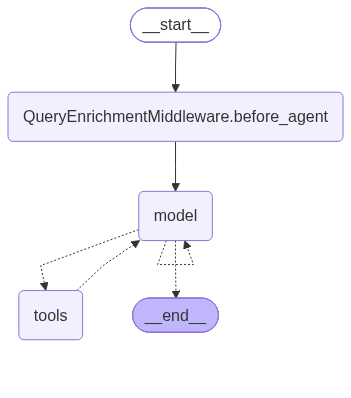

In [23]:
from IPython.display import Image, Markdown, display

display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

### 🚀 Launch the thing
Sends the test question to the agent on `thread-4`. Note the input is `{"messages": [...]}`, not a bare string. Yes, the bare string was a rookie move. We don't talk about it.

Expect a few minutes: the supervisor fans out to both subagents, then sometimes gets enthusiastic and asks one of them to double-check itself.

In [24]:
response = agent.invoke(
    {"messages": [ HumanMessage(content=decomposable_query),]},
    {"configurable": {"thread_id": "thread-4",}}
)

### 📜 The reveal
Pulls the last message's text and renders it as Markdown. The `[-1]['text']` poking is because the content comes back as a list of blocks, not a plain string. Because of course it does.

In [29]:
display(Markdown(response['messages'][-1].content[-1]['text']))

### USD to EUR

The latest indicative quote I could retrieve is **US$1 = €0.89287**. I couldn’t verify the quote’s update time, so treat it as an indication rather than a guaranteed live rate. The ECB’s [reference rates](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html) are published separately and may differ from live market quotes.

### European Central Bank policy

As of **13 October 2026**, the latest ECB rate decision I could verify was on **10 September**: the ECB raised its three key rates by **0.25 percentage point**, effective 16 September. The rates are **2.50%** for the deposit facility, **2.65%** for main refinancing operations, and **2.90%** for the marginal lending facility. The ECB cited persistent inflation pressures and said future decisions would depend on incoming data, with no preset path.

The ECB’s September projections put inflation at **3.0% in 2026, 2.5% in 2027 and 2.1% in 2028**. In an 8 October interview, policymaker Primož Dolenc said further increases might be needed, while stressing that timing and size would depend on the data. That was a policymaker’s comment, not a new rate decision.

- [ECB’s 10 September rate decision](https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260910~314e508016.en.html)
- [ECB account of its September meeting](https://www.ecb.europa.eu/press/accounts/2026/html/ecb.mg261008~a10153d090.en.html)
- [Reuters on Dolenc’s comments](https://www.reuters.com/world/europe/with-inflation-risks-upside-ecb-may-need-hike-more-dolenc-says-2026-10-08)

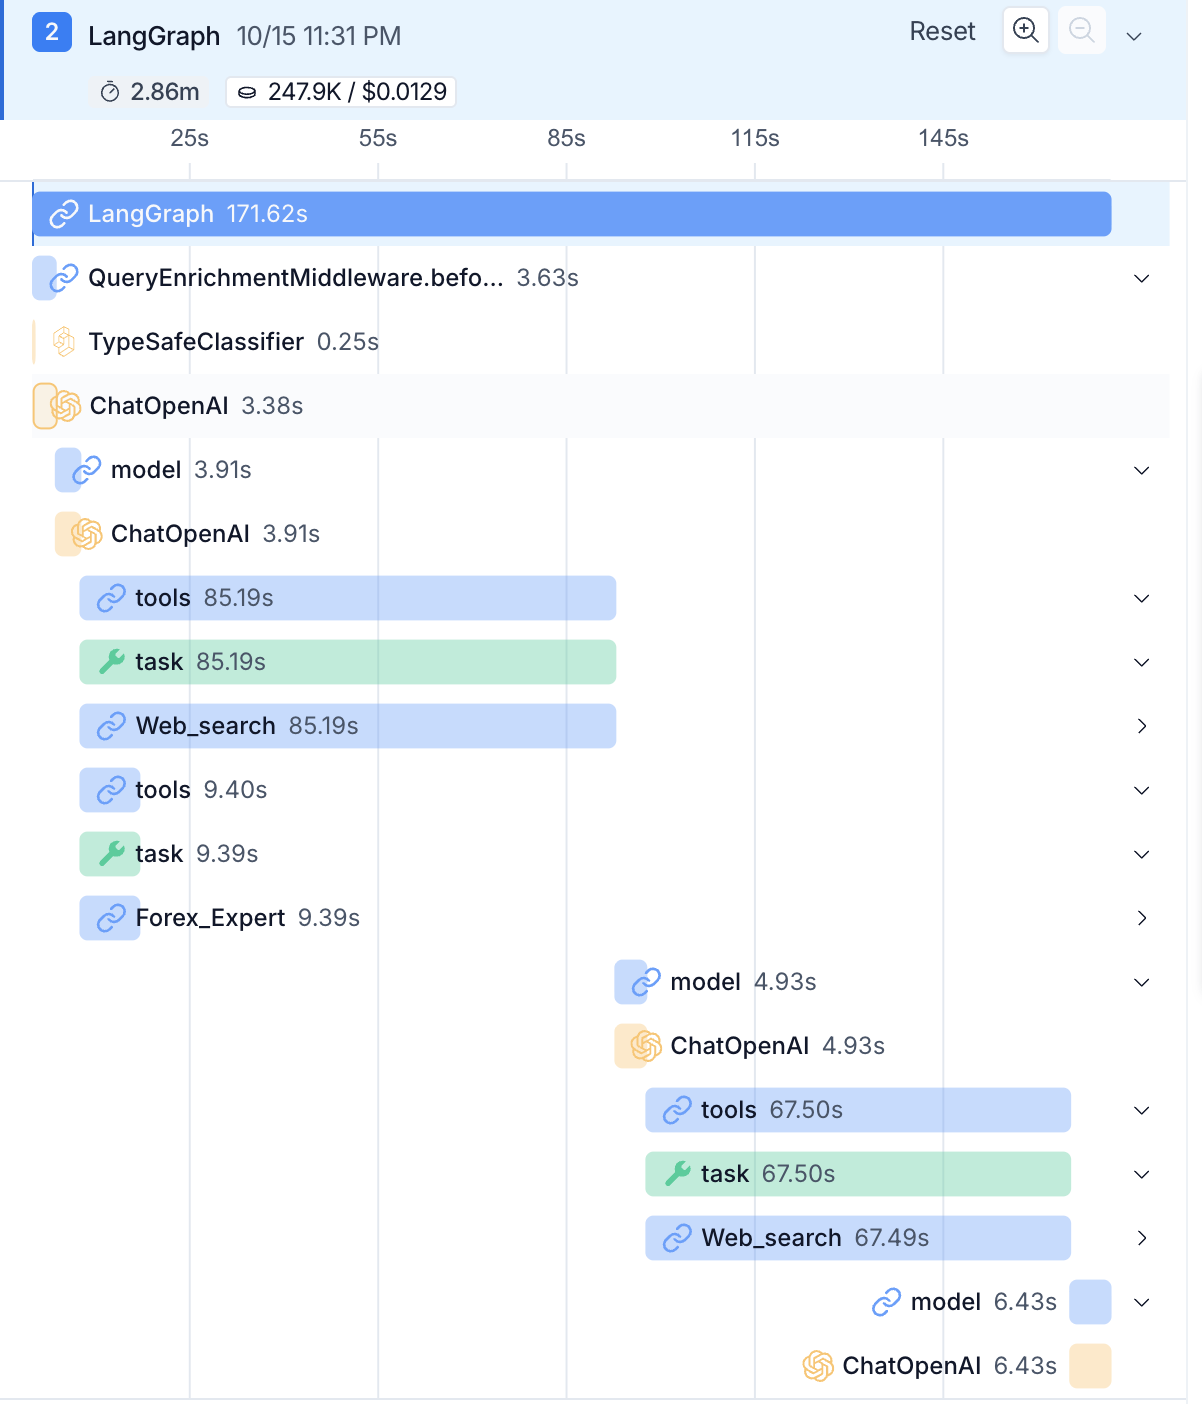

In [42]:
display(Image("../images/trace_decompose_query.png"))

Notice that it successfully decomposed the query and invoked the `ForexExpert` and `Web_search` sub agent at the same time so it worked! After analzying both results, it decided to invoke the `Web_search` subagent again to verify a claim, following which it congealed its findings into a coherent answer for us.

> And this is why you should not replace the supervisor agent with Jev! Jev does help routing only. But when it comes to reasoning or challenging queries, an LLM is better. 

### 🎭 The cast of test queries
One query per class the bouncer is meant to recognise: `direct` (a clean question), `enrichable` (Singlish that would make an English teacher weep), and `needs_clarification` (keyboard-mash, i.e. a cat walked across the keys). Notably missing: a `decomposable` one. That's the star of the main run above.

In [ ]:
direct_query = "What is the current exchange rate between USD and EUR?"
enrichable_query = "Usain Bolt fast how training he?"
needs_clarification_query = "fasdlkfaleuraoi34"

### 🔁 Run the gauntlet
Sends each test query through the full agent, each on its own `thread_{i}` so they don't contaminate each other's history. (Learned from `thread-2`, which was basically a crime scene.) Collects the final text of each reply into `answers`. Grab a coffee; subagents are not speed demons.

In [34]:
tests = [direct_query, enrichable_query, needs_clarification_query]
answers = []
for i, test in enumerate(tests):
    response = agent.invoke(
        {"messages": [ HumanMessage(content=test),]},
        {"configurable": {"thread_id": f"thread_{i}",}}
    )
    answers.append(response['messages'][-1].content[-1]['text'])

### 🪞 Show and tell
Renders each collected answer as Markdown, in the order the tests were run. Compare them against what you *expected* each class to do. Spoiler for the next cell: the middle one disappoints.

In [36]:
for _ in answers:
    display(Markdown(_))

The latest rate available to me is **1 USD ≈ 0.8929 EUR**. Exchange rates fluctuate, and your bank or exchange service may offer a different rate after fees or spreads.

Usain Bolt was extraordinarily fast: his 100-meter world record is **9.58 seconds**, and his 200-meter record is **19.19 seconds**. At his peak, he reached roughly **44–45 km/h (27–28 mph)**.

His training combined:
- **Sprint practice**—short, fast runs and starts
- **Strength work**—weights and exercises for power
- **Plyometrics**—jumps and explosive movements
- **Technique and mobility work**
- **Recovery**, including rest and treatment for injuries

He trained with a coach and tailored the work to his body and events. His speed came from training **and** exceptional natural ability—his routine isn’t something to copy without proper coaching.

I’m not sure what you mean by “fasdlkfaleuraoi34.” Could you clarify what you’d like help with?

It turned out that the confidence score for the enrichable query was 43%, so Jev elected to pass the query directly to the supervisor - which didn't actually give us the answer we wanted "How do we train to be as fast as Usain Bolt". 

> Fair warning to using Jev!